# 🧠 Student Social Media & Mental Health Prediction
## Phase 1 — Complete Machine Learning Workflow

**Goal:** Build a regression model that predicts a student's **Mental Health Score**  
based on their social media habits, lifestyle, and academic factors.

---
### Dataset columns
| Column | Type | Description |
|--------|------|-------------|
| Age | Numerical | Student age |
| Gender | Categorical | Male / Female / Other |
| Country | Categorical | Country of residence |
| Academic_Level | Categorical | High School / Undergraduate / Graduate |
| Most_Used_Platform | Categorical | Social media platform |
| Purpose_Of_Use | Categorical | Why they use social media |
| Avg_Daily_Usage_Hours | Numerical | Hours on social media per day |
| Daily_Unlocks | Numerical | Phone unlocks per day |
| Study_Hours | Numerical | Study hours per day |
| Physical_Activity_Hours | Numerical | Exercise hours per day |
| Sleep_Hours_Per_Night | Numerical | Sleep duration |
| Stress_Level | Ordinal | Low / Medium / High / Very High |
| **Mental_Health_Score** | **Target** | Score 1–10 (higher = better health) |

---
## Step 1 — Import Libraries

We import all the tools we need:
- **pandas / numpy** – data manipulation
- **matplotlib / seaborn** – visualisation
- **scikit-learn** – machine learning pipeline, models, evaluation
- **joblib** – saving the trained model

In [8]:
# ── Standard library ────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

# ── Data manipulation ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Scikit-learn: preprocessing ──────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ── Scikit-learn: models ─────────────────────────────────────────────────────
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# ── Scikit-learn: evaluation & splitting ────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ── Model saving ─────────────────────────────────────────────────────────────
import joblib
import os

# ── Plot style ────────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


---
## Step 2 — Load the Dataset

We load the CSV file from the `../data/` folder (one level up from notebooks).

In [9]:
DATA_PATH = '../data/student_social_media.csv'

df = pd.read_csv(DATA_PATH)
print(f'✅ Dataset loaded. Shape: {df.shape}')
print(f'   Rows: {df.shape[0]:,} | Columns: {df.shape[1]}')

✅ Dataset loaded. Shape: (5000, 13)
   Rows: 5,000 | Columns: 13


---
## Step 3 — Basic Data Exploration

We look at the first few rows, column types, and summary statistics to understand what we are working with.

In [10]:
# ── Shape ────────────────────────────────────────────────────────────────────
print('=' * 55)
print(f'  Dataset shape : {df.shape}')
print('=' * 55)

  Dataset shape : (5000, 13)


In [11]:
# ── Column names ─────────────────────────────────────────────────────────────
print('Column names:')
for col in df.columns:
    print(f'  • {col}')

Column names:
  • Age
  • Gender
  • Country
  • Academic_Level
  • Most_Used_Platform
  • Purpose_Of_Use
  • Avg_Daily_Usage_Hours
  • Daily_Unlocks
  • Study_Hours
  • Physical_Activity_Hours
  • Sleep_Hours_Per_Night
  • Stress_Level
  • Mental_Health_Score


In [12]:
# ── First 5 rows ──────────────────────────────────────────────────────────────
print('First 5 rows:')
df.head()

First 5 rows:


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [13]:
# ── DataFrame info (data types, non-null counts) ─────────────────────────────
print('DataFrame Info:')
df.info()

DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   str    
 2   Country                  5000 non-null   str    
 3   Academic_Level           5000 non-null   str    
 4   Most_Used_Platform       5000 non-null   str    
 5   Purpose_Of_Use           5000 non-null   str    
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   str    
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), str(6)
memory usage: 736.5 KB


In [14]:
# ── Summary statistics for numerical columns ──────────────────────────────────
print('Statistical Summary:')
df.describe().round(2)

Statistical Summary:


,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,20.82,5.08,171.45,3.01,1.75,6.63,6.23
std,1.74,1.65,42.86,1.64,0.67,1.22,1.28
min,18.00,1.00,62.00,0.30,-0.40,3.60,3.60
25%,19.00,3.80,140.00,1.50,1.30,5.60,5.10
50%,21.00,5.00,171.00,2.80,1.70,6.60,6.10
75%,22.00,6.30,204.00,4.20,2.20,7.50,7.10
max,24.00,8.80,273.00,8.30,4.10,9.90,9.40


---
## Step 4 — Missing Values & Duplicate Records

Real-world data often contains nulls and duplicates. We check and handle both.

In [15]:
# ── Missing values ────────────────────────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]

if missing_df.empty:
    print('✅ No missing values found — dataset is clean!')
else:
    print('⚠️  Missing values detected:')
    print(missing_df)

✅ No missing values found — dataset is clean!


In [16]:
# ── Duplicate rows ────────────────────────────────────────────────────────────
dup_count = df.duplicated().sum()
print(f'Duplicate rows: {dup_count}')

if dup_count > 0:
    df = df.drop_duplicates()
    print(f'✅ Duplicates removed. New shape: {df.shape}')
else:
    print('✅ No duplicate rows found.')

Duplicate rows: 2
✅ Duplicates removed. New shape: (4998, 13)


---
## Step 5 — Identify Numerical & Categorical Columns

We separate columns by type so we can apply the right transformations to each group.

In [17]:
TARGET = 'Mental_Health_Score'

# All columns except target
feature_cols = [c for c in df.columns if c != TARGET]

num_cols = df[feature_cols].select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df[feature_cols].select_dtypes(include=['object']).columns.tolist()

print(f'🎯 Target column : {TARGET}')
print(f'\n📊 Numerical features ({len(num_cols)}):')
for c in num_cols:
    print(f'  • {c}')
print(f'\n🏷️  Categorical features ({len(cat_cols)}):')
for c in cat_cols:
    print(f'  • {c}')

🎯 Target column : Mental_Health_Score

📊 Numerical features (6):
  • Age
  • Avg_Daily_Usage_Hours
  • Daily_Unlocks
  • Study_Hours
  • Physical_Activity_Hours
  • Sleep_Hours_Per_Night

🏷️  Categorical features (6):
  • Gender
  • Country
  • Academic_Level
  • Most_Used_Platform
  • Purpose_Of_Use
  • Stress_Level


In [18]:
# ── Unique values in each categorical column ──────────────────────────────────
print('Unique values per categorical column:\n')
for c in cat_cols:
    print(f'  {c}: {df[c].unique().tolist()}')

Unique values per categorical column:

  Gender: ['Male', 'Female']
  Country: ['Other', 'Canada', 'USA', 'India', 'Australia', 'UK', 'Germany', 'Bangladesh', 'Brazil', 'Japan', 'South Korea', 'France', 'Spain', 'Italy', 'Mexico', 'Russia', 'China', 'Sweden', 'Norway', 'Denmark', 'Netherlands', 'Belgium', 'Switzerland', 'Austria', 'Portugal', 'Greece', 'Ireland', 'New Zealand', 'Singapore', 'Malaysia', 'Thailand', 'Vietnam', 'Philippines', 'Indonesia', 'Taiwan', 'Hong Kong', 'Turkey', 'Israel', 'UAE', 'Egypt', 'Morocco', 'South Africa', 'Nigeria', 'Kenya', 'Ghana', 'Argentina', 'Chile', 'Colombia', 'Peru', 'Venezuela', 'Ecuador', 'Uruguay', 'Paraguay', 'Bolivia', 'Costa Rica', 'Panama', 'Jamaica', 'Trinidad', 'Bahamas', 'Iceland', 'Finland', 'Poland', 'Romania', 'Hungary', 'Czech Republic', 'Slovakia', 'Croatia', 'Serbia', 'Slovenia', 'Bulgaria', 'Estonia', 'Latvia', 'Lithuania', 'Ukraine', 'Moldova', 'Belarus', 'Kazakhstan', 'Uzbekistan', 'Kyrgyzstan', 'Tajikistan', 'Armenia', 'Georgi

---
## Step 6 — Exploratory Data Analysis (EDA)

We create **6 key plots** to visually understand patterns, distributions and relationships in the data.

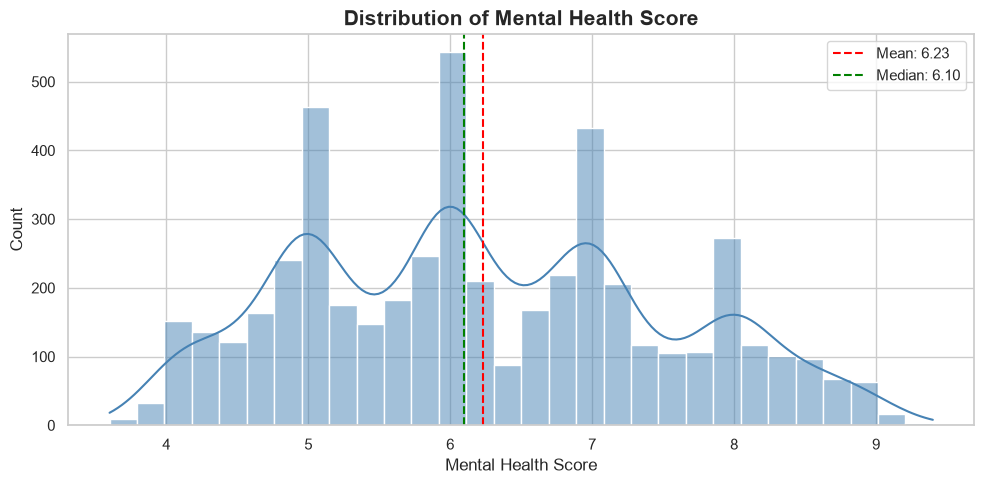

Mean: 6.23 | Median: 6.10 | Std: 1.28


In [19]:
# ── Plot 1: Mental Health Score distribution (Histogram + KDE) ───────────────
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df[TARGET], bins=30, kde=True, color='steelblue', ax=ax)
ax.set_title('Distribution of Mental Health Score', fontsize=15, fontweight='bold')
ax.set_xlabel('Mental Health Score')
ax.set_ylabel('Count')
ax.axvline(df[TARGET].mean(), color='red', linestyle='--', label=f'Mean: {df[TARGET].mean():.2f}')
ax.axvline(df[TARGET].median(), color='green', linestyle='--', label=f'Median: {df[TARGET].median():.2f}')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Mean: {df[TARGET].mean():.2f} | Median: {df[TARGET].median():.2f} | Std: {df[TARGET].std():.2f}')

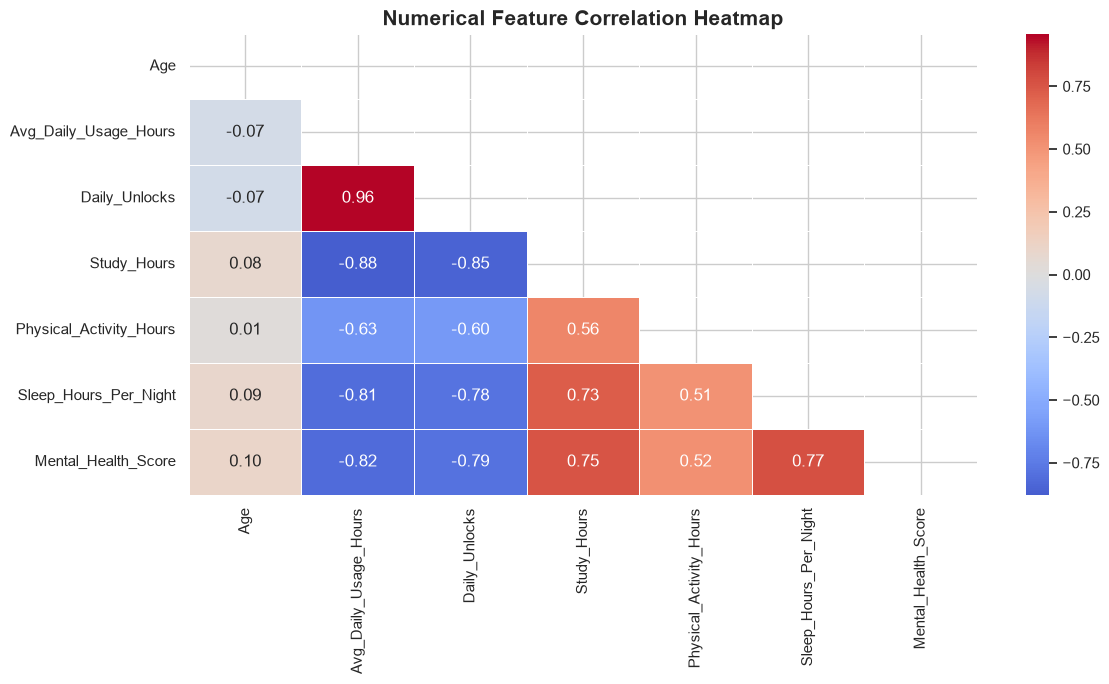


🔗 Feature correlation with Mental_Health_Score:
Avg_Daily_Usage_Hours     -0.816
Daily_Unlocks             -0.791
Sleep_Hours_Per_Night      0.766
Study_Hours                0.752
Physical_Activity_Hours    0.522
Age                        0.100
Name: Mental_Health_Score, dtype: float64


In [20]:
# ── Plot 2: Numerical Feature Correlation Heatmap ────────────────────────────
fig, ax = plt.subplots(figsize=(12, 7))
corr = df[num_cols + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # hide upper triangle
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', center=0, linewidths=0.5, ax=ax
)
ax.set_title('Numerical Feature Correlation Heatmap', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# Most correlated features with target
corr_target = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print('\n🔗 Feature correlation with Mental_Health_Score:')
print(corr_target.round(3))

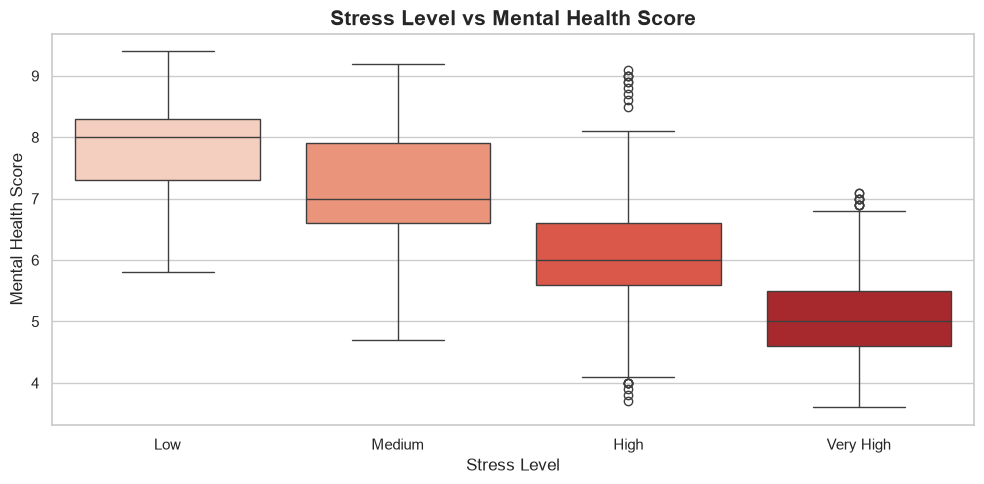

Mean Mental Health Score by Stress Level:
Stress_Level
Low          7.84
Medium       7.14
High         6.03
Very High    5.05
Name: Mental_Health_Score, dtype: float64


In [21]:
# ── Plot 3: Stress Level vs Mental Health Score (Boxplot) ─────────────────────
stress_order = ['Low', 'Medium', 'High', 'Very High']
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=df, x='Stress_Level', y=TARGET,
    order=stress_order, palette='Reds', ax=ax
)
ax.set_title('Stress Level vs Mental Health Score', fontsize=15, fontweight='bold')
ax.set_xlabel('Stress Level')
ax.set_ylabel('Mental Health Score')
plt.tight_layout()
plt.show()

print('Mean Mental Health Score by Stress Level:')
print(df.groupby('Stress_Level')[TARGET].mean().reindex(stress_order).round(2))

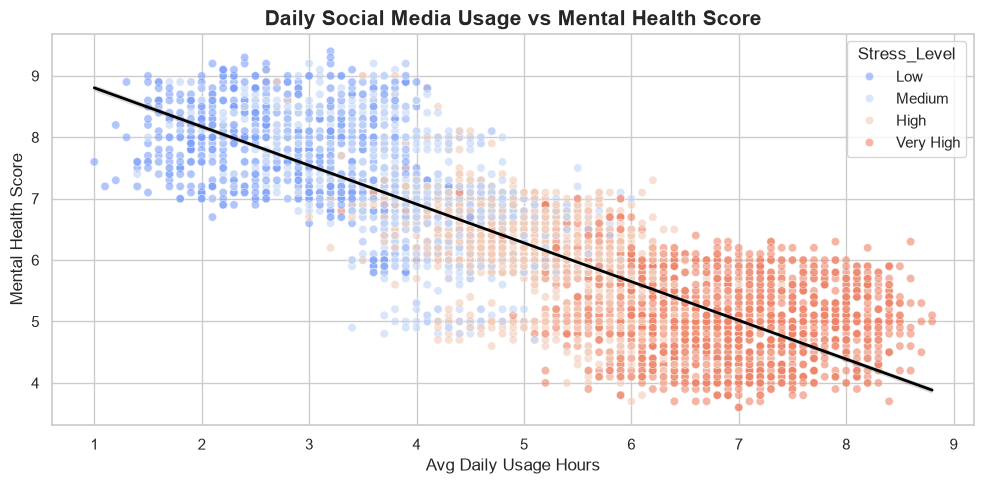

In [22]:
# ── Plot 4: Avg Daily Usage Hours vs Mental Health Score (Scatterplot) ────────
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(
    data=df, x='Avg_Daily_Usage_Hours', y=TARGET,
    hue='Stress_Level', palette='coolwarm',
    hue_order=stress_order, alpha=0.6, ax=ax
)
# regression trend line
sns.regplot(
    data=df, x='Avg_Daily_Usage_Hours', y=TARGET,
    scatter=False, color='black', line_kws={'linewidth': 2}, ax=ax
)
ax.set_title('Daily Social Media Usage vs Mental Health Score', fontsize=15, fontweight='bold')
ax.set_xlabel('Avg Daily Usage Hours')
ax.set_ylabel('Mental Health Score')
plt.tight_layout()
plt.show()

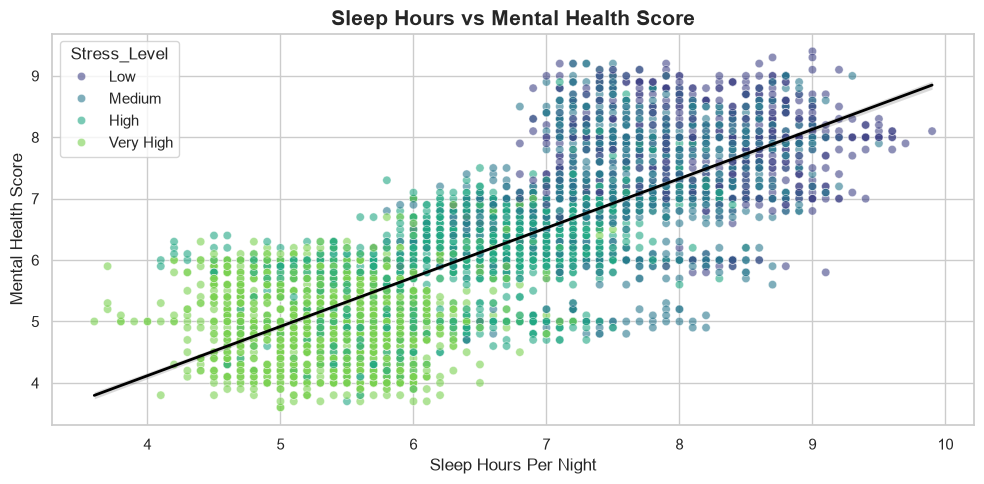

In [23]:
# ── Plot 5: Sleep Hours vs Mental Health Score (Scatterplot) ──────────────────
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(
    data=df, x='Sleep_Hours_Per_Night', y=TARGET,
    hue='Stress_Level', palette='viridis',
    hue_order=stress_order, alpha=0.6, ax=ax
)
sns.regplot(
    data=df, x='Sleep_Hours_Per_Night', y=TARGET,
    scatter=False, color='black', line_kws={'linewidth': 2}, ax=ax
)
ax.set_title('Sleep Hours vs Mental Health Score', fontsize=15, fontweight='bold')
ax.set_xlabel('Sleep Hours Per Night')
ax.set_ylabel('Mental Health Score')
plt.tight_layout()
plt.show()

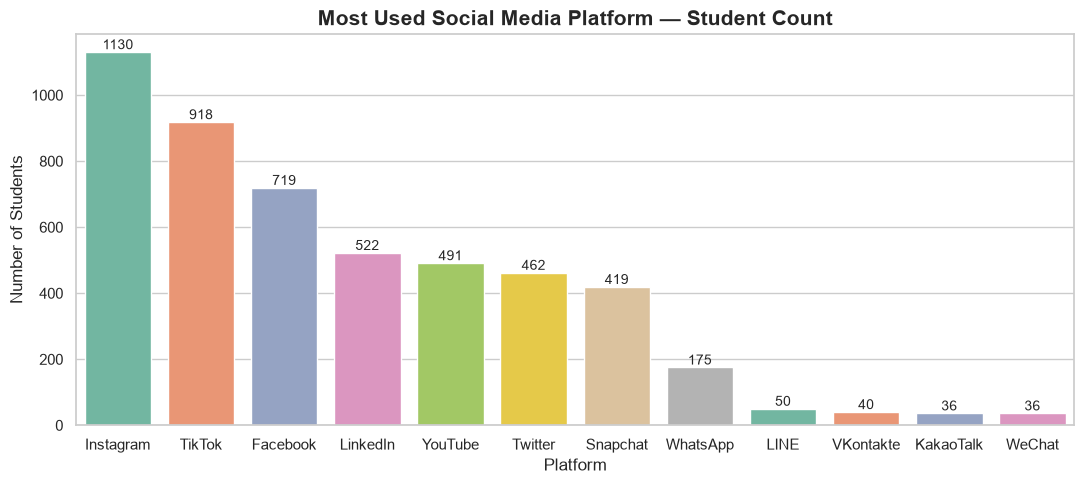

Most_Used_Platform
Instagram    1130
TikTok        918
Facebook      719
LinkedIn      522
YouTube       491
Twitter       462
Snapchat      419
WhatsApp      175
LINE           50
VKontakte      40
KakaoTalk      36
WeChat         36
Name: count, dtype: int64


In [24]:
# ── Plot 6: Most Used Platform Countplot ──────────────────────────────────────
platform_counts = df['Most_Used_Platform'].value_counts()
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(
    x=platform_counts.index, y=platform_counts.values,
    palette='Set2', ax=ax
)
ax.set_title('Most Used Social Media Platform — Student Count', fontsize=15, fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Number of Students')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()
print(platform_counts)

---
## Step 7 — Outlier Detection using IQR

**IQR (Interquartile Range)** = Q3 − Q1  
Values below `Q1 − 1.5×IQR` or above `Q3 + 1.5×IQR` are considered outliers.  
We detect them but do **not** blindly remove all — only clearly invalid ones.

In [25]:
print('=' * 60)
print('  Outlier Detection (IQR method) — Numerical Columns')
print('=' * 60)

outlier_summary = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = df[(df[col] < lower) | (df[col] > upper)].shape[0]
    outlier_summary.append({
        'Column': col,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Lower Fence': round(lower, 2),
        'Upper Fence': round(upper, 2),
        'Outlier Count': outlier_count
    })

outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df.to_string(index=False))

  Outlier Detection (IQR method) — Numerical Columns
                 Column    Q1    Q3  IQR  Lower Fence  Upper Fence  Outlier Count
                    Age  19.0  22.0  3.0        14.50        26.50              0
  Avg_Daily_Usage_Hours   3.8   6.3  2.5         0.05        10.05              0
          Daily_Unlocks 140.0 204.0 64.0        44.00       300.00              0
            Study_Hours   1.5   4.2  2.7        -2.55         8.25              2
Physical_Activity_Hours   1.3   2.2  0.9        -0.05         3.55             22
  Sleep_Hours_Per_Night   5.6   7.5  1.9         2.75        10.35              0


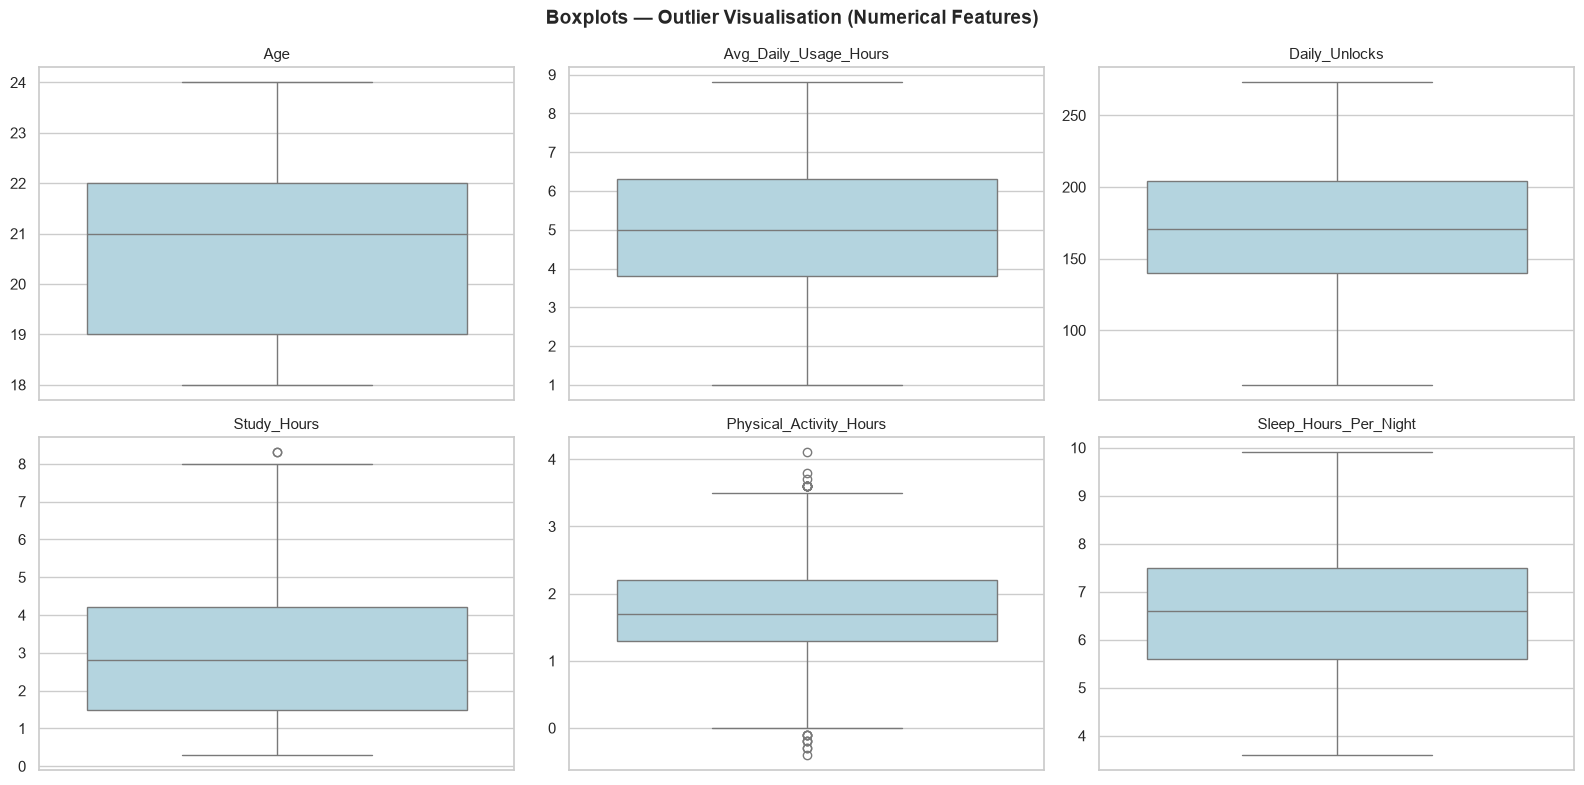

In [26]:
# ── Boxplot to visually see outliers ─────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='lightblue')
    axes[i].set_title(col, fontsize=11)
    axes[i].set_ylabel('')

# hide any unused subplot slots
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots — Outlier Visualisation (Numerical Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Step 8 — Handle Invalid Negative Physical Activity Values

Physical activity hours **cannot be negative** in real life.  
We detect any such records and replace them with the column median (safe imputation).

In [27]:
neg_phys = (df['Physical_Activity_Hours'] < 0).sum()
print(f'Negative Physical_Activity_Hours values: {neg_phys}')

if neg_phys > 0:
    median_val = df.loc[df['Physical_Activity_Hours'] >= 0, 'Physical_Activity_Hours'].median()
    df.loc[df['Physical_Activity_Hours'] < 0, 'Physical_Activity_Hours'] = median_val
    print(f'✅ Replaced {neg_phys} invalid value(s) with median ({median_val:.2f})')
else:
    print('✅ No negative Physical_Activity_Hours values — data is valid!')

print(f'   Min value now: {df["Physical_Activity_Hours"].min():.2f}')

Negative Physical_Activity_Hours values: 10
✅ Replaced 10 invalid value(s) with median (1.70)
   Min value now: 0.00


---
## Step 9 — Skewness Analysis & Handling

**Skewness** measures how asymmetric a distribution is.  
- |skew| > 1 → **Highly skewed** → apply `np.log1p()` transformation  
- 0.5 < |skew| ≤ 1 → **Moderately skewed** → apply `np.sqrt()` transformation  
- |skew| ≤ 0.5 → **Approximately normal** → no transformation needed  

We handle skewness **inside the pipeline** via custom transformers, so we only *analyse* it here.

In [28]:
print('Skewness of numerical columns (before pipeline):\n')
skew_df = df[num_cols + [TARGET]].skew().round(3).reset_index()
skew_df.columns = ['Column', 'Skewness']

def classify_skew(s):
    if abs(s) > 1:   return 'High — log1p recommended'
    if abs(s) > 0.5: return 'Moderate — sqrt recommended'
    return 'Normal — no transform needed'

skew_df['Assessment'] = skew_df['Skewness'].apply(classify_skew)
print(skew_df.to_string(index=False))

Skewness of numerical columns (before pipeline):

                 Column  Skewness                   Assessment
                    Age     0.155 Normal — no transform needed
  Avg_Daily_Usage_Hours     0.006 Normal — no transform needed
          Daily_Unlocks     0.002 Normal — no transform needed
            Study_Hours     0.436 Normal — no transform needed
Physical_Activity_Hours     0.076 Normal — no transform needed
  Sleep_Hours_Per_Night     0.124 Normal — no transform needed
    Mental_Health_Score     0.207 Normal — no transform needed


In [29]:
# ── Flag high-skew numerical columns (for reference) ─────────────────────────
high_skew_cols = skew_df[
    (skew_df['Column'].isin(num_cols)) & (skew_df['Skewness'].abs() > 1)
]['Column'].tolist()

print(f'Columns with |skewness| > 1: {high_skew_cols}')
print('\nNote: Skewness will be handled inside the sklearn Pipeline')
print('      using FunctionTransformer(np.log1p) on high-skew features.')

Columns with |skewness| > 1: []

Note: Skewness will be handled inside the sklearn Pipeline
      using FunctionTransformer(np.log1p) on high-skew features.


---
## Step 10 — Encode Categorical Columns (Analysis)

We identify **how** each categorical column will be encoded inside the Pipeline:

| Column | Encoding | Reason |
|--------|----------|--------|
| Stress_Level | **OrdinalEncoder** | Has natural order: Low < Medium < High < Very High |
| Gender | **OneHotEncoder** | Nominal — no natural order |
| Country | **OneHotEncoder** | Nominal |
| Academic_Level | **OneHotEncoder** | Nominal (categorical, not strictly ordinal) |
| Most_Used_Platform | **OneHotEncoder** | Nominal |
| Purpose_Of_Use | **OneHotEncoder** | Nominal |

In [30]:
# ── Define ordinal and nominal columns ───────────────────────────────────────
ORDINAL_COL  = 'Stress_Level'
ORDINAL_CATS = [['Low', 'Medium', 'High', 'Very High']]   # order matters!

NOMINAL_COLS = [c for c in cat_cols if c != ORDINAL_COL]

print(f'Ordinal column  : {ORDINAL_COL}  → OrdinalEncoder')
print(f'Nominal columns : {NOMINAL_COLS}  → OneHotEncoder')

# Value counts for each categorical column
print('\nValue counts per categorical column:')
for c in cat_cols:
    print(f'\n{c}:')
    print(df[c].value_counts())

Ordinal column  : Stress_Level  → OrdinalEncoder
Nominal columns : ['Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use']  → OneHotEncoder

Value counts per categorical column:

Gender:
Gender
Male      2634
Female    2364
Name: count, dtype: int64

Country:
Country
Other         1879
India          389
USA            354
Canada         230
Australia      198
              ... 
Montenegro       1
Bosnia           1
Kuwait           1
Yemen            1
Syria            1
Name: count, Length: 111, dtype: int64

Academic_Level:
Academic_Level
Undergraduate    3630
Graduate          918
High School       450
Name: count, dtype: int64

Most_Used_Platform:
Most_Used_Platform
Instagram    1130
TikTok        918
Facebook      719
LinkedIn      522
YouTube       491
Twitter       462
Snapchat      419
WhatsApp      175
LINE           50
VKontakte      40
KakaoTalk      36
WeChat         36
Name: count, dtype: int64

Purpose_Of_Use:
Purpose_Of_Use
Entertainment    2551


---
## Step 11 — Feature / Target Split & Train-Test Split

In [31]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'✅ Feature matrix X : {X.shape}')
print(f'   Target vector  y : {y.shape}')
print(f'\n   Training set  : {X_train.shape[0]:,} rows')
print(f'   Test set      : {X_test.shape[0]:,} rows')

✅ Feature matrix X : (4998, 12)
   Target vector  y : (4998,)

   Training set  : 3,998 rows
   Test set      : 1,000 rows


---
## Step 12 — Build the ColumnTransformer

A **ColumnTransformer** applies different transformations to different columns simultaneously:
- Numerical → `StandardScaler` (zero mean, unit variance)
- Ordinal → `OrdinalEncoder` (Low=0, Medium=1, High=2, Very High=3)
- Nominal → `OneHotEncoder` (creates binary dummy columns)

By keeping this inside the Pipeline, **the test set is never seen during fit** — no data leakage.

In [32]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline as SKPipeline

# ── High-skew numerical columns get log1p before scaling ─────────────────────
# (Daily_Unlocks is typically skewed; we apply log1p + StandardScaler)
log_num_cols  = [c for c in num_cols if c in high_skew_cols]  # e.g. ['Daily_Unlocks']
norm_num_cols = [c for c in num_cols if c not in log_num_cols] # rest of num cols

print(f'Log-transform numerical cols : {log_num_cols}')
print(f'Standard numerical cols      : {norm_num_cols}')

# ── Sub-pipeline for high-skew numerical columns ──────────────────────────────
log_num_transformer = SKPipeline(steps=[
    ('log1p', FunctionTransformer(np.log1p, validate=True)),
    ('scaler', StandardScaler())
])

# ── Sub-pipeline for normal numerical columns ─────────────────────────────────
num_transformer = SKPipeline(steps=[
    ('scaler', StandardScaler())
])

# ── ColumnTransformer ─────────────────────────────────────────────────────────
transformers = []

if log_num_cols:
    transformers.append(('log_num', log_num_transformer, log_num_cols))
if norm_num_cols:
    transformers.append(('num', num_transformer, norm_num_cols))

transformers += [
    ('ordinal', OrdinalEncoder(categories=ORDINAL_CATS), [ORDINAL_COL]),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), NOMINAL_COLS)
]

preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')

print('\n✅ ColumnTransformer built successfully!')
print(f'   Total transformer steps: {len(transformers)}')

Log-transform numerical cols : []
Standard numerical cols      : ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night']

✅ ColumnTransformer built successfully!
   Total transformer steps: 3


---
## Step 13 — Build Preprocessing + Model Pipelines

Each model gets wrapped in its own Pipeline:
```
Raw Input → ColumnTransformer (preprocess) → Regressor (predict)
```
This ensures preprocessing + prediction are always applied together — essential for deployment.

In [33]:
models = {
    'Linear Regression': LinearRegression(),
    'KNN Regressor': KNeighborsRegressor(n_neighbors=7),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

print('✅ Pipelines created for all models:')
for name in pipelines:
    print(f'   • {name}')

✅ Pipelines created for all models:
   • Linear Regression
   • KNN Regressor
   • Decision Tree
   • Random Forest


---
## Step 14 — Train All Models & Step 15 — Evaluate with MAE, MSE, RMSE, R²

In [34]:
results = []
trained_pipelines = {}

print('Training models...\n')
print(f'{"Model":<22} {"MAE":>8} {"MSE":>8} {"RMSE":>8} {"R² Score":>10}')
print('-' * 60)

for name, pipe in pipelines.items():
    # Train
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    # Predict on test set
    y_pred = pipe.predict(X_test)

    # Metrics
    mae  = mean_absolute_error(y_test, y_pred)
    mse  = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_test, y_pred)

    results.append({'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2 Score': r2})
    print(f'{name:<22} {mae:>8.4f} {mse:>8.4f} {rmse:>8.4f} {r2:>10.4f}')

print('-' * 60)
results_df = pd.DataFrame(results).sort_values('R2 Score', ascending=False).reset_index(drop=True)

Training models...

Model                       MAE      MSE     RMSE   R² Score
------------------------------------------------------------
Linear Regression        0.4735   0.3751   0.6124     0.7899
KNN Regressor            0.3559   0.2430   0.4930     0.8639
Decision Tree            0.4181   0.3186   0.5645     0.8215
Random Forest            0.3663   0.2365   0.4863     0.8675
------------------------------------------------------------


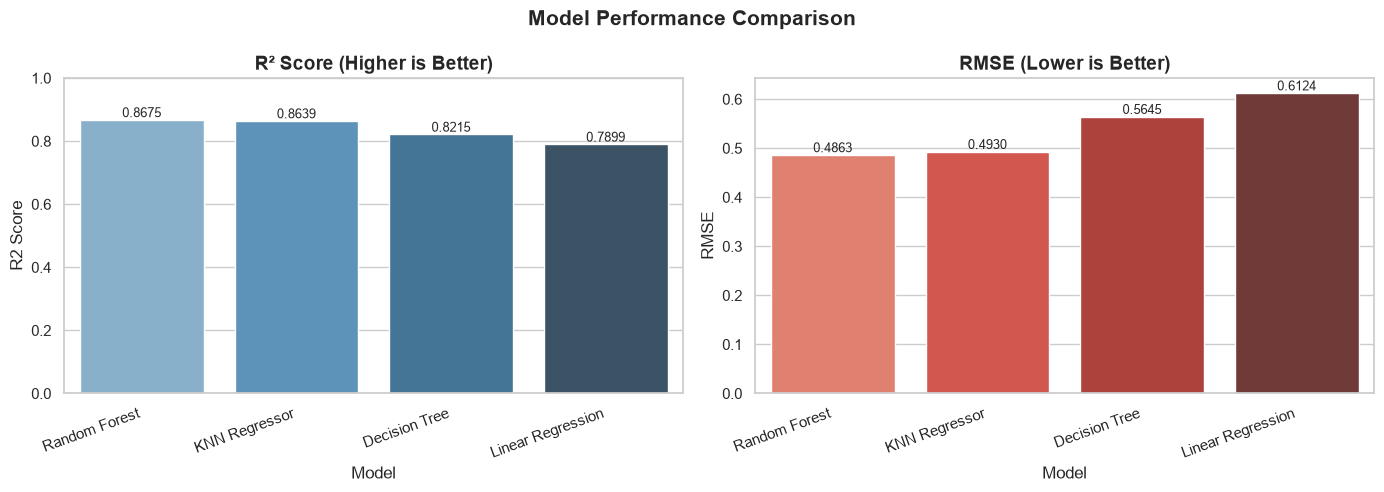


📊 Ranked Results:
            Model    MAE    MSE   RMSE  R2 Score
    Random Forest 0.3663 0.2365 0.4863    0.8675
    KNN Regressor 0.3559 0.2430 0.4930    0.8639
    Decision Tree 0.4181 0.3186 0.5645    0.8215
Linear Regression 0.4735 0.3751 0.6124    0.7899


In [35]:
# ── Visual comparison ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R² Score (higher is better)
sns.barplot(data=results_df, x='Model', y='R2 Score', palette='Blues_d', ax=axes[0])
axes[0].set_title('R² Score (Higher is Better)', fontweight='bold')
axes[0].set_ylim(0, 1)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.4f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha='right')

# RMSE (lower is better)
sns.barplot(data=results_df, x='Model', y='RMSE', palette='Reds_d', ax=axes[1])
axes[1].set_title('RMSE (Lower is Better)', fontweight='bold')
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.4f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right')

plt.suptitle('Model Performance Comparison', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print('\n📊 Ranked Results:')
print(results_df.round(4).to_string(index=False))

---
## Step 16 — Select the Best Model

  🏆 Best Model : Random Forest
  📈 R² Score   : 0.8675  (86.75% variance explained)
  📉 RMSE       : 0.4863


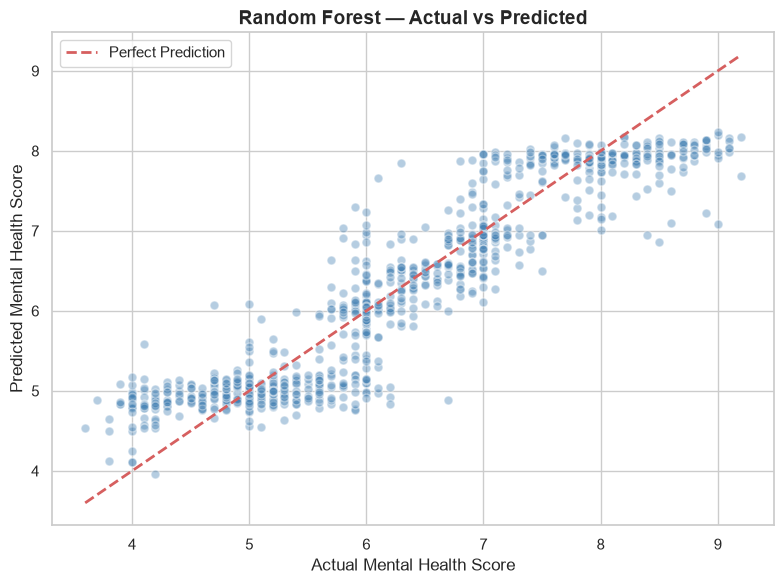

In [36]:
best_model_name = results_df.iloc[0]['Model']   # top R2
best_pipeline   = trained_pipelines[best_model_name]
best_r2         = results_df.iloc[0]['R2 Score']
best_rmse       = results_df.iloc[0]['RMSE']

print('=' * 55)
print(f'  🏆 Best Model : {best_model_name}')
print(f'  📈 R² Score   : {best_r2:.4f}  ({best_r2*100:.2f}% variance explained)')
print(f'  📉 RMSE       : {best_rmse:.4f}')
print('=' * 55)

# Actual vs Predicted plot for best model
y_pred_best = best_pipeline.predict(X_test)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred_best, alpha=0.4, color='steelblue', edgecolors='white', s=40)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
ax.set_xlabel('Actual Mental Health Score', fontsize=12)
ax.set_ylabel('Predicted Mental Health Score', fontsize=12)
ax.set_title(f'{best_model_name} — Actual vs Predicted', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

---
## Step 17 — Save the Best Pipeline using Joblib

We save the **complete fitted pipeline** (preprocessor + model) as a single `.pkl` file.  
This means at prediction time, we only need to load one file and call `.predict(X_new)`.

In [37]:
MODEL_DIR  = '../models'
MODEL_PATH = os.path.join(MODEL_DIR, 'mental_health_model.pkl')

os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(best_pipeline, MODEL_PATH)
print(f'✅ Model saved → {MODEL_PATH}')

# Verify the saved model works
loaded_pipeline = joblib.load(MODEL_PATH)
sample_pred = loaded_pipeline.predict(X_test.iloc[:5])
print(f'\n🔍 Verification — predictions on first 5 test rows:')
print(f'  Predicted : {sample_pred.round(2)}')
print(f'  Actual    : {y_test.iloc[:5].values}')
print('\n✅ Model load & predict verified successfully!')

✅ Model saved → ../models\mental_health_model.pkl

🔍 Verification — predictions on first 5 test rows:
  Predicted : [4.91 5.92 4.5  5.18 7.94]
  Actual    : [5.3 5.8 3.8 5.6 7.5]

✅ Model load & predict verified successfully!


In [38]:
# ── Print the feature names expected by the pipeline ─────────────────────────
# This is important for the FastAPI backend input schema
print('📋 Feature columns expected by the model (in order):')
for i, col in enumerate(X.columns, 1):
    dtype = str(X[col].dtype)
    sample = X[col].iloc[0]
    print(f'  {i:2}. {col:<30} dtype={dtype:<10} example={sample}')

📋 Feature columns expected by the model (in order):
   1. Age                            dtype=int64      example=21
   2. Gender                         dtype=str        example=Male
   3. Country                        dtype=str        example=Other
   4. Academic_Level                 dtype=str        example=Undergraduate
   5. Most_Used_Platform             dtype=str        example=Facebook
   6. Purpose_Of_Use                 dtype=str        example=Networking
   7. Avg_Daily_Usage_Hours          dtype=float64    example=4.0
   8. Daily_Unlocks                  dtype=int64      example=134
   9. Study_Hours                    dtype=float64    example=4.5
  10. Physical_Activity_Hours        dtype=float64    example=2.2
  11. Sleep_Hours_Per_Night          dtype=float64    example=6.7
  12. Stress_Level                   dtype=str        example=Medium


---
## ✅ Phase 1 Complete!

### Summary

| Step | Description | Status |
|------|-------------|--------|
| 1 | Imported all libraries | ✅ |
| 2 | Loaded CSV dataset (5000 rows, 13 cols) | ✅ |
| 3 | Explored shape, columns, head, info, describe | ✅ |
| 4 | Checked missing values & duplicates | ✅ |
| 5 | Identified numerical & categorical columns | ✅ |
| 6 | Created 6 EDA plots | ✅ |
| 7 | Detected outliers using IQR | ✅ |
| 8 | Handled invalid negative physical activity values | ✅ |
| 9 | Analysed & planned skewness handling | ✅ |
| 10 | Planned categorical encoding strategy | ✅ |
| 11 | Split features/target & train/test | ✅ |
| 12 | Built ColumnTransformer | ✅ |
| 13 | Built full preprocessing + model Pipelines | ✅ |
| 14 | Trained 4 regression models | ✅ |
| 15 | Evaluated with MAE, MSE, RMSE, R² | ✅ |
| 16 | Selected best model | ✅ |
| 17 | Saved complete pipeline with Joblib | ✅ |

### Next → Phase 2: FastAPI Backend
The saved model at `../models/mental_health_model.pkl` will be loaded by the FastAPI backend.